In [1]:
# =========================================
# 📁 1. SETUP & IMPORTS
# =========================================

# =========================================
# ⚙️ INSTALL REQUIRED LIBRARIES
# =========================================

!pip -q install nltk
!pip -q install spacy
!pip -q install transformers
!pip -q install ultralytics

!python -m spacy download en_core_web_sm

# =========================================
# ===== PYTHON =====
# =========================================

import os
import json
import re
import random
from collections import Counter

# =========================================
# ===== DATA =====
# =========================================

import numpy as np
import pandas as pd

# =========================================
# ===== DEEP LEARNING =====
# =========================================

import torch
import torch.nn as nn

from torch.utils.data import (

    Dataset,
    DataLoader,
    random_split
)

# =========================================
# ===== COMPUTER VISION =====
# =========================================

from torchvision import transforms

from torchvision.models import (

    resnet18,
    ResNet18_Weights
)

# =========================================
# ===== IMAGE PROCESSING =====
# =========================================

from PIL import Image

# =========================================
# ===== VISUALIZATION =====
# =========================================

import matplotlib.pyplot as plt
import seaborn as sns

# =========================================
# ===== NLP / METRICS =====
# =========================================

import nltk

from nltk.translate.bleu_score import (

    corpus_bleu,
    SmoothingFunction
)

from nltk.translate.meteor_score import (

    meteor_score
)

# =========================================
# ===== NLP / MULTIMODAL =====
# =========================================

import spacy

from transformers import (

    GPT2LMHeadModel,
    GPT2TokenizerFast
)

from ultralytics import YOLO

# =========================================
# ===== UTILITIES =====
# =========================================

import cv2

from tqdm import tqdm

# =========================================
# 📥 DOWNLOAD NLTK DATA
# =========================================

nltk.download("wordnet")

nltk.download("omw-1.4")

# =========================================
# ⚙️ DEVICE CONFIGURATION
# =========================================

DEVICE = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"
)

print("Using device :", DEVICE)

# =========================================
# 🔒 REPRODUCIBILITY
# =========================================

SEED = 42

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(SEED)

# =========================================
# 📂 DATASET PATHS
# =========================================

BASE_DIR = "/kaggle/input/datasets/nikhil7280/coco-image-caption"

IMG_DIR = os.path.join(

    BASE_DIR,

    "train2014/train2014"
)

ANN_PATH = os.path.join(

    BASE_DIR,

    "annotations_trainval2014/annotations/captions_train2014.json"
)

# =========================================
# ⚙️ HYPERPARAMETERS
# =========================================

MAX_LEN = 25

BATCH_SIZE = 64

EMBED_SIZE = 512

HIDDEN_SIZE = 512

VOCAB_SIZE = 20000

EPOCHS = 20

LEARNING_RATE = 3e-4

DROPOUT = 0.3

PATIENCE = 3

# =========================================
# 🚀 DATALOADER OPTIMIZATION
# =========================================

NUM_WORKERS = 2

PIN_MEMORY = torch.cuda.is_available()

# =========================================
# 📌 CHECK PATHS
# =========================================

print("Images Path Exists :",

      os.path.exists(IMG_DIR))

print("Annotations Exists :",

      os.path.exists(ANN_PATH))

# =========================================
# 🧠 LOAD SPACY MODEL
# =========================================

nlp = spacy.load(

    "en_core_web_sm"
)

print("✅ SpaCy loaded")

# =========================================
# 🖼️ LOAD YOLO
# =========================================

yolo = YOLO("yolov8n.pt")

print("✅ YOLO loaded")

# =========================================
# 🤖 LOAD GPT2
# =========================================

tokenizer = GPT2TokenizerFast.from_pretrained(
    "gpt2"
)

gpt2 = GPT2LMHeadModel.from_pretrained(
    "gpt2"
).to(DEVICE)

gpt2.eval()

print("✅ GPT2 loaded")

# =========================================
# ✅ FINAL CHECK
# =========================================

print("\n✅ Setup completed successfully")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 26.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 81.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...


Using device : cuda
Images Path Exists : True
Annotations Exists : True
✅ SpaCy loaded
✅ YOLO loaded


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

✅ GPT2 loaded

✅ Setup completed successfully


In [2]:
# =========================================
# 📁 2. LOAD & CLEAN CAPTIONS
# =========================================

def clean_caption(text):

    # =====================================
    # 🔡 LOWERCASE
    # =====================================

    text = text.lower()

    # =====================================
    # 🔥 REMOVE SPECIAL CHARACTERS
    # =====================================

    text = re.sub(

        r"[^a-z\s]",

        "",

        text
    )

    # =====================================
    # 🔄 REMOVE MULTIPLE SPACES
    # =====================================

    text = re.sub(

        r"\s+",

        " ",

        text
    ).strip()

    return text

# =========================================
# 📖 LOAD COCO ANNOTATIONS
# =========================================

with open(ANN_PATH, "r") as f:

    annotations = json.load(f)

print("Number of annotations :",

      len(annotations["annotations"]))

# =========================================
# 📝 BUILD CAPTIONS DICTIONARY
# =========================================

caps_dict = {}

for ann in annotations["annotations"]:

    img_id = ann["image_id"]

    caption = clean_caption(

        ann["caption"]
    )

    # =====================================
    # 🚫 SKIP EMPTY CAPTIONS
    # =====================================

    if len(caption.split()) == 0:

        continue

    caps_dict.setdefault(

        img_id,

        []
    ).append(caption)

# =========================================
# 🔥 REDUCE DATASET SIZE
# =========================================

MAX_IMAGES = 80000

ids = list(caps_dict.keys())[:MAX_IMAGES]

caps_dict = {

    k: caps_dict[k]

    for k in ids
}

# =========================================
# 📊 DATASET STATISTICS
# =========================================

num_captions = sum(

    len(v)

    for v in caps_dict.values()
)

print("Number of images :",

      len(caps_dict))

print("Number of captions :",

      num_captions)

print("Average captions per image :",

      round(num_captions / len(caps_dict), 2))

# =========================================
# 🔍 SAMPLE
# =========================================

sample_id = ids[0]

print("\nSample Image ID :",

      sample_id)

print("Sample Captions :")

for c in caps_dict[sample_id][:3]:

    print("-", c)

Number of annotations : 414113
Number of images : 80000
Number of captions : 400194
Average captions per image : 5.0

Sample Image ID : 318556
Sample Captions :
- a very clean and well decorated empty bathroom
- a blue and white bathroom with butterfly themed wall tiles
- a bathroom with a border of butterflies and blue paint on the walls above it


In [3]:
# =========================================
# 📚 VOCABULARY CONSTRUCTION
# =========================================

all_words = []

for captions in caps_dict.values():

    for caption in captions:

        all_words.extend(
            caption.split()
        )

# =========================================
# 📊 WORD FREQUENCIES
# =========================================

counter = Counter(all_words)

# garder mots fréquents uniquement
vocab = [
    word
    for word, freq in counter.most_common(VOCAB_SIZE)
    if freq >= 5
]

print("Vocabulary size :", len(vocab))

# =========================================
# 🔤 SPECIAL TOKENS
# =========================================

SPECIAL_TOKENS = {
    "<pad>": 0,
    "<start>": 1,
    "<end>": 2,
    "<unk>": 3
}

word2idx = {
    word: idx + len(SPECIAL_TOKENS)
    for idx, word in enumerate(vocab)
}

word2idx.update(SPECIAL_TOKENS)

idx2word = {
    idx: word
    for word, idx in word2idx.items()
}

print("Total vocabulary :", len(word2idx))

Vocabulary size : 8662
Total vocabulary : 8666


In [4]:
# =========================================
# 📦 COCO DATASET
# =========================================

class CocoDataset(Dataset):

    def __init__(self, captions_dict):

        self.ids = list(captions_dict.keys())

        self.data = captions_dict

        # =====================================
        # 🖼️ IMAGE TRANSFORMS
        # =====================================

        self.transform = transforms.Compose([

            transforms.Resize((224, 224)),

            transforms.ToTensor(),

            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    # =====================================
    # 📏 DATASET SIZE
    # =====================================

    def __len__(self):

        return len(self.ids)

    # =====================================
    # 📥 GET ITEM
    # =====================================

    def __getitem__(self, idx):

        img_id = self.ids[idx]

        # =====================================
        # 🖼️ IMAGE PATH
        # =====================================

        img_path = os.path.join(
            IMG_DIR,
            f"COCO_train2014_{img_id:012d}.jpg"
        )

        image = Image.open(
            img_path
        ).convert("RGB")

        image = self.transform(image)

        # =====================================
        # 📝 RANDOM CAPTION
        # =====================================

        caption = random.choice(
            self.data[img_id]
        )

        tokens = (
            ["<start>"]
            + caption.split()
            + ["<end>"]
        )

        encoded = [

            word2idx.get(
                token,
                word2idx["<unk>"]
            )

            for token in tokens
        ]

        # =====================================
        # ✂️ TRUNCATE
        # =====================================

        encoded = encoded[:MAX_LEN]

        # garantir token <end>
        if encoded[-1] != word2idx["<end>"]:

            encoded[-1] = word2idx["<end>"]

        # =====================================
        # 📏 PADDING
        # =====================================

        length = len(encoded)

        if length < MAX_LEN:

            encoded += [

                word2idx["<pad>"]

            ] * (MAX_LEN - length)

        return (
            image,
            torch.tensor(encoded),
            length
        )

In [5]:
# =========================================
# 🚀 DATALOADERS
# =========================================

dataset = CocoDataset(caps_dict)

# =========================================
# 📊 TRAIN / VALIDATION SPLIT
# =========================================

train_size = int(0.9 * len(dataset))

val_size = len(dataset) - train_size

train_data, val_data = random_split(

    dataset,

    [train_size, val_size],

    generator=torch.Generator().manual_seed(SEED)
)

# =========================================
# 🚀 TRAIN LOADER
# =========================================

train_loader = DataLoader(

    train_data,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY
)

# =========================================
# 🚀 VALIDATION LOADER
# =========================================

val_loader = DataLoader(

    val_data,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY
)

print("Train batches :", len(train_loader))
print("Validation batches :", len(val_loader))

Train batches : 1125
Validation batches : 125


In [6]:
# =========================================
# 🧪 DATASET TEST
# =========================================

images, captions, lengths = next(

    iter(train_loader)
)

print("Image batch shape :", images.shape)

print("Caption batch shape :", captions.shape)

print("Lengths :", lengths[:5])

# =========================================
# 🔍 SAMPLE CAPTION
# =========================================

sample = captions[0].tolist()

decoded = [

    idx2word[idx]

    for idx in sample

    if idx not in [

        word2idx["<pad>"]
    ]
]

print("Decoded caption :")

print(decoded)

Image batch shape : torch.Size([64, 3, 224, 224])
Caption batch shape : torch.Size([64, 25])
Lengths : tensor([14, 10, 15, 13, 11])
Decoded caption :
['<start>', 'there', 'is', 'a', 'small', 'red', 'fire', 'hydrant', 'amongst', 'some', 'small', 'pine', 'trees', '<end>']


In [7]:
# =========================================
# 🧠 CNN ENCODER
# =========================================

class CNNEncoder(nn.Module):

    def __init__(self, train_cnn=False):

        super().__init__()

        # =====================================
        # 🔥 PRETRAINED RESNET18
        # =====================================

        resnet = resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        # supprimer average pooling + FC
        modules = list(
            resnet.children()
        )[:-2]

        self.backbone = nn.Sequential(
            *modules
        )

        # =====================================
        # 🔒 FREEZE CNN
        # =====================================

        for param in self.backbone.parameters():

            param.requires_grad = train_cnn

    # =====================================
    # 🚀 FORWARD
    # =====================================

    def forward(self, images):

        """
        images:
            (B, 3, 224, 224)

        return:
            (B, 49, 512)
        """

        features = self.backbone(images)

        # (B, 512, 7, 7)

        B, C, H, W = features.shape

        # flatten spatial dimensions

        features = features.view(
            B,
            C,
            H * W
        )

        # (B, 512, 49)

        features = features.permute(
            0,
            2,
            1
        )

        # (B, 49, 512)

        return features

In [8]:
# =========================================
# 🔁 BRNN ENCODER
# =========================================

class BRNNEncoder(nn.Module):

    def __init__(

        self,

        input_dim=512,

        hidden_dim=256
    ):

        super().__init__()

        self.hidden_dim = hidden_dim

        # =====================================
        # 🔥 BIDIRECTIONAL GRU
        # =====================================

        self.brnn = nn.GRU(

            input_dim,

            hidden_dim,

            batch_first=True,

            bidirectional=True
        )

    # =====================================
    # 🚀 FORWARD
    # =====================================

    def forward(self, features):

        """
        features:
            (B, 49, 512)

        return:
            (B, 49, hidden_dim*2)
        """

        outputs, _ = self.brnn(features)

        return outputs

In [9]:
# =========================================
# 🎯 BAHDANAU ATTENTION
# =========================================

class BahdanauAttention(nn.Module):

    def __init__(

        self,

        encoder_dim=512,

        decoder_dim=512,

        attention_dim=256
    ):

        super().__init__()

        # =====================================
        # 🔥 ATTENTION LAYERS
        # =====================================

        self.W = nn.Linear(
            encoder_dim,
            attention_dim
        )

        self.U = nn.Linear(
            decoder_dim,
            attention_dim
        )

        self.V = nn.Linear(
            attention_dim,
            1
        )

    # =====================================
    # 🚀 FORWARD
    # =====================================

    def forward(

        self,

        features,

        hidden
    ):

        """
        features:
            (B, 49, encoder_dim)

        hidden:
            (B, decoder_dim)
        """

        # =====================================
        # 🔥 EXPAND HIDDEN
        # =====================================

        hidden = hidden.unsqueeze(1)

        # (B, 1, decoder_dim)

        # =====================================
        # 🔥 ENERGY SCORES
        # =====================================

        energy = torch.tanh(

            self.W(features)

            +

            self.U(hidden)
        )

        # (B, 49, attention_dim)

        scores = self.V(energy).squeeze(2)

        # (B, 49)

        # =====================================
        # 🔥 ATTENTION WEIGHTS
        # =====================================

        alpha = torch.softmax(
            scores,
            dim=1
        )

        # =====================================
        # 🔥 CONTEXT VECTOR
        # =====================================

        context = (

            features
            *
            alpha.unsqueeze(2)

        ).sum(dim=1)

        # (B, encoder_dim)

        return context, alpha

In [10]:
# =========================================
# 🧪 TEST CNN ENCODER
# =========================================

cnn = CNNEncoder().to(DEVICE)

images, captions, lengths = next(
    iter(train_loader)
)

images = images.to(DEVICE)

features = cnn(images)

print("CNN Features Shape :")

print(features.shape)

# Expected:
# (B, 49, 512)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 213MB/s]


CNN Features Shape :
torch.Size([64, 49, 512])


In [11]:
# =========================================
# 🧪 TEST BRNN ENCODER
# =========================================

brnn = BRNNEncoder().to(DEVICE)

outputs = brnn(features)

print("BRNN Output Shape :")

print(outputs.shape)

# Expected:
# (B, 49, 512)

BRNN Output Shape :
torch.Size([64, 49, 512])


In [12]:
# =========================================
# 🧪 TEST ATTENTION
# =========================================

attention = BahdanauAttention().to(DEVICE)

hidden = torch.randn(
    images.size(0),
    HIDDEN_SIZE
).to(DEVICE)

context, alpha = attention(
    features,
    hidden
)

print("Context Shape :")
print(context.shape)

print("Attention Shape :")
print(alpha.shape)

# Expected:
# context -> (B, 512)
# alpha   -> (B, 49)

Context Shape :
torch.Size([64, 512])
Attention Shape :
torch.Size([64, 49])


In [13]:
# =========================================
# 🧠 LSTM DECODER
# =========================================

class Decoder(nn.Module):

    def __init__(

        self,

        vocab_size,

        embed_dim=EMBED_SIZE,

        hidden_dim=HIDDEN_SIZE,

        encoder_dim=512,

        use_attention=False
    ):

        super().__init__()

        self.use_attention = use_attention

        # =====================================
        # 🔤 WORD EMBEDDINGS
        # =====================================

        self.embedding = nn.Embedding(

            vocab_size,

            embed_dim,

            padding_idx=word2idx["<pad>"]
        )

        self.dropout = nn.Dropout(
            DROPOUT
        )

        # =====================================
        # 🔥 LSTM INPUT SIZE
        # =====================================

        if use_attention:

            input_dim = (
                embed_dim
                +
                encoder_dim
            )

        else:

            input_dim = embed_dim

        # =====================================
        # 🔁 LSTM CELL
        # =====================================

        self.lstm = nn.LSTMCell(

            input_dim,

            hidden_dim
        )

        # =====================================
        # 🎯 OUTPUT LAYER
        # =====================================

        self.fc = nn.Linear(

            hidden_dim,

            vocab_size
        )

    # =====================================
    # 🚀 ONE DECODING STEP
    # =====================================

    def forward_step(

        self,

        word,

        hidden,

        cell,

        context=None
    ):

        """
        word:
            (B,)

        hidden/cell:
            (B, hidden_dim)

        context:
            (B, encoder_dim)
        """

        # =====================================
        # 🔤 EMBEDDING
        # =====================================

        embedding = self.embedding(word)

        embedding = self.dropout(
            embedding
        )

        # =====================================
        # 🔥 CONCAT ATTENTION CONTEXT
        # =====================================

        if self.use_attention:

            x = torch.cat(

                [embedding, context],

                dim=1
            )

        else:

            x = embedding

        # =====================================
        # 🔁 LSTM STEP
        # =====================================

        hidden, cell = self.lstm(

            x,

            (hidden, cell)
        )

        # =====================================
        # 🎯 VOCAB PREDICTION
        # =====================================

        outputs = self.fc(hidden)

        return outputs, hidden, cell

In [14]:
# =========================================
# 🥇 NIC MODEL
# =========================================

class NIC(nn.Module):

    def __init__(

        self,

        encoder,

        decoder
    ):

        super().__init__()

        self.encoder = encoder

        self.decoder = decoder

    # =====================================
    # 🚀 FORWARD
    # =====================================

    def forward(

        self,

        images,

        captions
    ):

        B = images.size(0)

        device = images.device

        # =====================================
        # 🧠 CNN FEATURES
        # =====================================

        features = self.encoder(images)

        # (B, 49, 512)

        # global average pooling

        features = features.mean(dim=1)

        # (B, 512)

        # =====================================
        # 🔥 INITIAL STATES
        # =====================================

        hidden = torch.zeros(

            B,

            HIDDEN_SIZE,

            device=device
        )

        cell = torch.zeros(

            B,

            HIDDEN_SIZE,

            device=device
        )

        outputs = []

        # =====================================
        # 🔁 TEACHER FORCING
        # =====================================

        for t in range(captions.size(1)):

            word = captions[:, t]

            out, hidden, cell = (

                self.decoder.forward_step(

                    word,

                    hidden,

                    cell
                )
            )

            outputs.append(out)

        outputs = torch.stack(
            outputs,
            dim=1
        )

        return outputs

### 

In [15]:
# =========================================
# 🥈 ATTENTION MODEL
# =========================================

class AttnModel(nn.Module):

    def __init__(

        self,

        encoder,

        decoder,

        attention
    ):

        super().__init__()

        self.encoder = encoder

        self.decoder = decoder

        self.attention = attention

    # =====================================
    # 🚀 FORWARD
    # =====================================

    def forward(

        self,

        images,

        captions
    ):

        B = images.size(0)

        device = images.device

        # =====================================
        # 🧠 CNN FEATURES
        # =====================================

        features = self.encoder(images)

        # =====================================
        # 🔥 INITIAL STATES
        # =====================================

        hidden = torch.zeros(

            B,

            HIDDEN_SIZE,

            device=device
        )

        cell = torch.zeros(

            B,

            HIDDEN_SIZE,

            device=device
        )

        outputs = []

        # =====================================
        # 🔁 DECODING LOOP
        # =====================================

        for t in range(captions.size(1)):

            word = captions[:, t]

            # attention weights

            context, alpha = self.attention(

                features,

                hidden
            )

            out, hidden, cell = (

                self.decoder.forward_step(

                    word,

                    hidden,

                    cell,

                    context
                )
            )

            outputs.append(out)

        outputs = torch.stack(
            outputs,
            dim=1
        )

        return outputs

In [16]:
# =========================================
# 🥉 BRNN + ATTENTION MODEL
# =========================================

class BRNN_Attn_Model(nn.Module):

    def __init__(

        self,

        cnn,

        brnn,

        decoder,

        attention
    ):

        super().__init__()

        self.cnn = cnn

        self.brnn = brnn

        self.decoder = decoder

        self.attention = attention

    # =====================================
    # 🚀 FORWARD
    # =====================================

    def forward(

        self,

        images,

        captions
    ):

        B = images.size(0)

        device = images.device

        # =====================================
        # 🧠 CNN FEATURES
        # =====================================

        features = self.cnn(images)

        # =====================================
        # 🔁 BRNN FEATURES
        # =====================================

        features = self.brnn(features)

        # =====================================
        # 🔥 INITIAL STATES
        # =====================================

        hidden = torch.zeros(

            B,

            HIDDEN_SIZE,

            device=device
        )

        cell = torch.zeros(

            B,

            HIDDEN_SIZE,

            device=device
        )

        outputs = []

        # =====================================
        # 🔁 DECODING
        # =====================================

        for t in range(captions.size(1)):

            word = captions[:, t]

            context, alpha = self.attention(

                features,

                hidden
            )

            out, hidden, cell = (

                self.decoder.forward_step(

                    word,

                    hidden,

                    cell,

                    context
                )
            )

            outputs.append(out)

        outputs = torch.stack(
            outputs,
            dim=1
        )

        return outputs

In [17]:
# =========================================
# 🧪 TEST MODELS
# =========================================

encoder = CNNEncoder().to(DEVICE)

attention = BahdanauAttention().to(DEVICE)

brnn = BRNNEncoder().to(DEVICE)

decoder_no_attn = Decoder(

    len(word2idx),

    use_attention=False

).to(DEVICE)

decoder_attn = Decoder(

    len(word2idx),

    use_attention=True

).to(DEVICE)

# =====================================
# 📦 SAMPLE BATCH
# =====================================

images, captions, lengths = next(
    iter(train_loader)
)

images = images.to(DEVICE)

captions = captions.to(DEVICE)

# =====================================
# 🥇 NIC
# =====================================

model_nic = NIC(

    encoder,

    decoder_no_attn

).to(DEVICE)

outputs_nic = model_nic(
    images,
    captions
)

print("NIC Output Shape :")

print(outputs_nic.shape)

# =====================================
# 🥈 ATTENTION
# =====================================

model_attn = AttnModel(

    encoder,

    decoder_attn,

    attention

).to(DEVICE)

outputs_attn = model_attn(
    images,
    captions
)

print("Attention Output Shape :")

print(outputs_attn.shape)

# =====================================
# 🥉 BRNN + ATTENTION
# =====================================

model_brnn = BRNN_Attn_Model(

    encoder,

    brnn,

    decoder_attn,

    attention

).to(DEVICE)

outputs_brnn = model_brnn(
    images,
    captions
)

print("BRNN + Attention Output Shape :")

print(outputs_brnn.shape)

# Expected:
# (B, MAX_LEN, vocab_size)

NIC Output Shape :
torch.Size([64, 25, 8666])
Attention Output Shape :
torch.Size([64, 25, 8666])
BRNN + Attention Output Shape :
torch.Size([64, 25, 8666])


In [18]:
# =========================================
# 🎯 LOSS FUNCTION
# =========================================

criterion = nn.CrossEntropyLoss(

    ignore_index=word2idx["<pad>"]
)

In [19]:
# =========================================
# 🚀 TRAIN ONE EPOCH
# =========================================

def train_one_epoch(

    model,

    loader,

    optimizer
):

    model.train()

    total_loss = 0

    for images, captions, lengths in tqdm(loader):

        images = images.to(DEVICE)

        captions = captions.to(DEVICE)

        # =====================================
        # 🔥 RESET GRADIENTS
        # =====================================

        optimizer.zero_grad()

        # =====================================
        # 🔥 FORWARD
        # =====================================

        outputs = model(

            images,

            captions[:, :-1]
        )

        targets = captions[:, 1:]

        # =====================================
        # 🔄 RESHAPE
        # =====================================

        outputs = outputs.reshape(

            -1,

            outputs.size(-1)
        )

        targets = targets.reshape(-1)

        # =====================================
        # 🎯 LOSS
        # =====================================

        loss = criterion(

            outputs,

            targets
        )

        # =====================================
        # 🔙 BACKPROP
        # =====================================

        loss.backward()

        # =====================================
        # ✂️ GRADIENT CLIPPING
        # =====================================

        torch.nn.utils.clip_grad_norm_(

            model.parameters(),

            max_norm=5
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [20]:
# =========================================
# 📊 VALIDATION
# =========================================

def evaluate(

    model,

    loader
):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for images, captions, lengths in loader:

            images = images.to(DEVICE)

            captions = captions.to(DEVICE)

            outputs = model(

                images,

                captions[:, :-1]
            )

            targets = captions[:, 1:]

            outputs = outputs.reshape(

                -1,

                outputs.size(-1)
            )

            targets = targets.reshape(-1)

            loss = criterion(

                outputs,

                targets
            )

            total_loss += loss.item()

    return total_loss / len(loader)

In [21]:
# =========================================
# 🏆 TRAIN MODEL
# =========================================

def train_model(

    model,

    model_name
):

    model = model.to(DEVICE)

    # =====================================
    # 🔥 OPTIMIZER
    # =====================================

    optimizer = torch.optim.Adam(

        model.parameters(),

        lr=LEARNING_RATE
    )

    # =====================================
    # 📉 LR SCHEDULER
    # =====================================

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(

        optimizer,

        mode='min',

        factor=0.5,

        patience=1
    )

    # =====================================
    # 📊 HISTORY
    # =====================================

    history = {

        "train_loss": [],

        "val_loss": []
    }

    best_loss = float("inf")

    best_epoch = 0

    patience_counter = 0

    print(f"\n🚀 Training {model_name}\n")

    # =====================================
    # 🔁 EPOCH LOOP
    # =====================================

    for epoch in range(EPOCHS):

        train_loss = train_one_epoch(

            model,

            train_loader,

            optimizer
        )

        val_loss = evaluate(

            model,

            val_loader
        )

        scheduler.step(val_loss)

        # =====================================
        # 📊 SAVE HISTORY
        # =====================================

        history["train_loss"].append(
            train_loss
        )

        history["val_loss"].append(
            val_loss
        )

        print(

            f"[{model_name}] "

            f"Epoch {epoch+1}/{EPOCHS} | "

            f"Train Loss: {train_loss:.4f} | "

            f"Val Loss: {val_loss:.4f}"
        )

        # =====================================
        # 💾 SAVE BEST MODEL
        # =====================================

        if val_loss < best_loss:

            best_loss = val_loss

            best_epoch = epoch + 1

            patience_counter = 0

            torch.save(

                model.state_dict(),

                f"best_{model_name}.pth"
            )

        else:

            patience_counter += 1

        # =====================================
        # ⛔ EARLY STOPPING
        # =====================================

        if patience_counter >= PATIENCE:

            print(

                f"\n⛔ Early stopping "

                f"for {model_name}"
            )

            break

    print(

        f"\n✅ Best Epoch: {best_epoch}"

        f"\n✅ Best Validation Loss: "

        f"{best_loss:.4f}"
    )

    return history

In [22]:
# =========================================
# 🥇 TRAIN NIC
# =========================================

encoder = CNNEncoder().to(DEVICE)

decoder = Decoder(

    len(word2idx),

    use_attention=False

).to(DEVICE)

model_nic = NIC(

    encoder,

    decoder
)

history_nic = train_model(

    model_nic,

    "nic"
)

# =========================================
# 🥈 TRAIN ATTENTION
# =========================================

encoder = CNNEncoder().to(DEVICE)

attention = BahdanauAttention().to(DEVICE)

decoder = Decoder(

    len(word2idx),

    use_attention=True

).to(DEVICE)

model_attn = AttnModel(

    encoder,

    decoder,

    attention
)

history_attn = train_model(

    model_attn,

    "attention"
)

# =========================================
# 🥉 TRAIN BRNN + ATTENTION
# =========================================

cnn = CNNEncoder().to(DEVICE)

brnn = BRNNEncoder().to(DEVICE)

attention = BahdanauAttention().to(DEVICE)

decoder = Decoder(

    len(word2idx),

    use_attention=True

).to(DEVICE)

model_brnn = BRNN_Attn_Model(

    cnn,

    brnn,

    decoder,

    attention
)

history_brnn = train_model(

    model_brnn,

    "brnn"
)


🚀 Training nic



100%|██████████| 1125/1125 [08:50<00:00,  2.12it/s]


[nic] Epoch 1/20 | Train Loss: 4.1631 | Val Loss: 3.6027


100%|██████████| 1125/1125 [04:52<00:00,  3.85it/s]


[nic] Epoch 2/20 | Train Loss: 3.4740 | Val Loss: 3.3151


...

[brnn] Epoch 18/20 | Train Loss: 2.3077 | Val Loss: 2.4614


100%|██████████| 1125/1125 [05:08<00:00,  3.65it/s]


[brnn] Epoch 19/20 | Train Loss: 2.3014 | Val Loss: 2.4776


100%|██████████| 1125/1125 [05:10<00:00,  3.62it/s]


[brnn] Epoch 20/20 | Train Loss: 2.2822 | Val Loss: 2.4523

✅ Best Epoch: 20
✅ Best Validation Loss: 2.4523


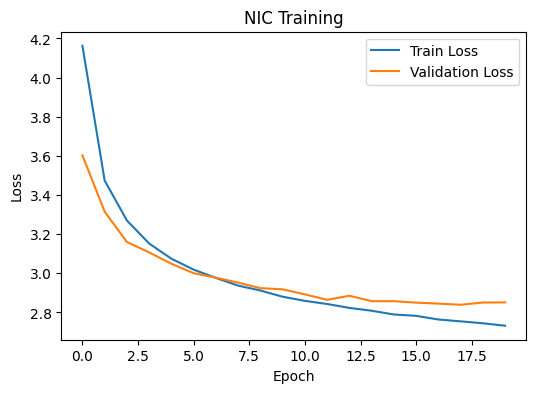

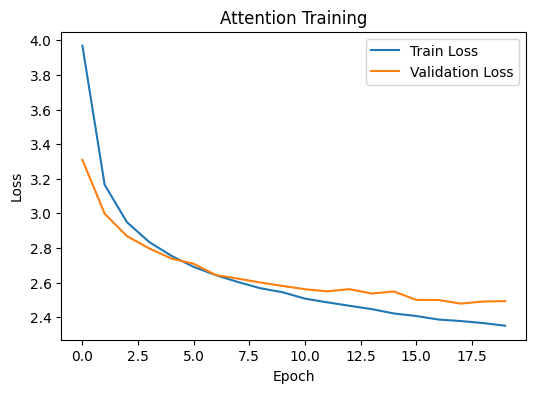

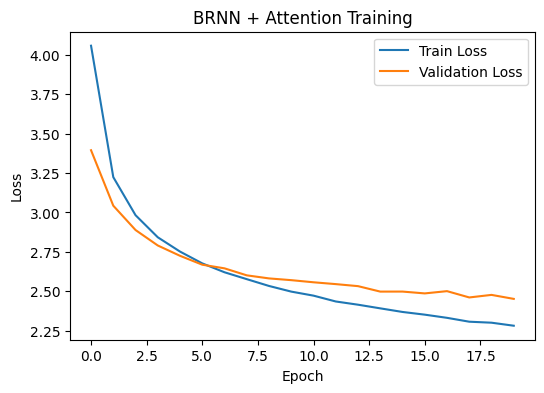

In [23]:
# =========================================
# 📉 PLOT TRAINING CURVES
# =========================================

def plot_history(

    history,

    title
):

    plt.figure(figsize=(6,4))

    plt.plot(

        history["train_loss"],

        label="Train Loss"
    )

    plt.plot(

        history["val_loss"],

        label="Validation Loss"
    )

    plt.title(title)

    plt.xlabel("Epoch")

    plt.ylabel("Loss")

    plt.legend()

    plt.show()

# =====================================
# 🔍 VISUALIZE
# =====================================

plot_history(
    history_nic,
    "NIC Training"
)

plot_history(
    history_attn,
    "Attention Training"
)

plot_history(
    history_brnn,
    "BRNN + Attention Training"
)

In [24]:
# =========================================
# 🧠 GENERATE CAPTION
# =========================================

def generate_caption(

    model,

    image,

    max_len=20,

    return_attention=False
):

    model.eval()

    attentions = []

    result = []

    with torch.no_grad():

        image = image.unsqueeze(0).to(DEVICE)

        # =====================================
        # 🧠 ENCODER
        # =====================================

        if hasattr(model, "cnn"):

            features = model.cnn(image)

            features = model.brnn(features)

        else:

            features = model.encoder(image)

        # =====================================
        # 🔥 INITIAL STATES
        # =====================================

        hidden = torch.zeros(

            1,

            HIDDEN_SIZE,

            device=DEVICE
        )

        cell = torch.zeros(

            1,

            HIDDEN_SIZE,

            device=DEVICE
        )

        word = torch.tensor(

            [word2idx["<start>"]],

            device=DEVICE
        )

        # =====================================
        # 🔁 GREEDY DECODING
        # =====================================

        for _ in range(max_len):

            # =================================
            # 🔥 ATTENTION
            # =================================

            if hasattr(model, "attention"):

                context, alpha = model.attention(

                    features,

                    hidden
                )

                attentions.append(

                    alpha.squeeze(0)

                    .cpu()

                    .numpy()
                )

                outputs, hidden, cell = (

                    model.decoder.forward_step(

                        word,

                        hidden,

                        cell,

                        context
                    )
                )

            # =================================
            # 🥇 NIC
            # =================================

            else:

                outputs, hidden, cell = (

                    model.decoder.forward_step(

                        word,

                        hidden,

                        cell
                    )
                )

            # =================================
            # 🔤 NEXT WORD
            # =================================

            word = outputs.argmax(1)

            token = word.item()

            if token == word2idx["<end>"]:

                break

            result.append(

                idx2word.get(

                    token,

                    "<unk>"
                )
            )

        caption = " ".join(result)

        if return_attention:

            return caption, attentions

        return caption

In [25]:
# =========================================
# 🔥 SHOW ATTENTION MAPS
# =========================================

def show_attention(

    image_tensor,

    words,

    attentions
):

    # =====================================
    # 🔄 DENORMALIZE IMAGE
    # =====================================

    mean = torch.tensor(

        [0.485, 0.456, 0.406]

    ).view(3,1,1)

    std = torch.tensor(

        [0.229, 0.224, 0.225]

    ).view(3,1,1)

    image = image_tensor.cpu()

    image = image * std + mean

    image = image.permute(

        1,2,0

    ).numpy()

    image = np.clip(image, 0, 1)

    # =====================================
    # 📊 FIGURE
    # =====================================

    fig = plt.figure(figsize=(15,10))

    for t in range(min(len(words), 9)):

        ax = fig.add_subplot(

            3,

            3,

            t+1
        )

        ax.set_title(words[t])

        # =================================
        # 🔥 ATTENTION MAP
        # =================================

        size = int(
            np.sqrt(
                len(attentions[t])
            )
        )

        attn = attentions[t].reshape(
            size,
            size
        )

        attn = cv2.resize(

            attn,

            (224,224)
        )

        ax.imshow(image)

        ax.imshow(

            attn,

            alpha=0.5,

            cmap="jet"
        )

        ax.axis("off")

    plt.tight_layout()

    plt.show()

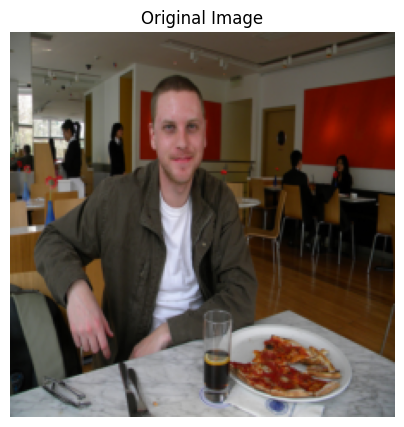

Generated Caption :
a man in a kitchen with a knife and fork


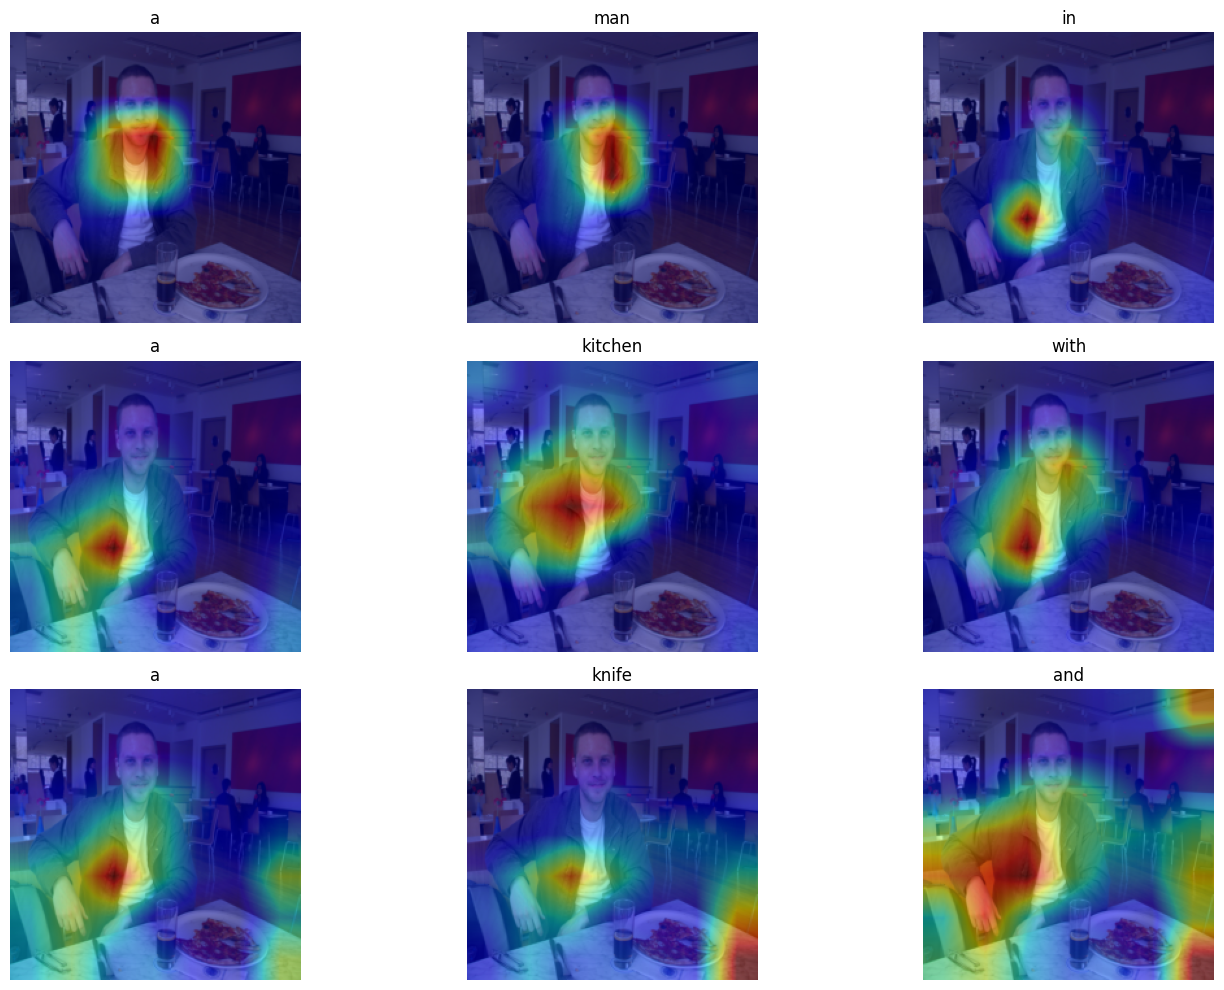

In [26]:
# =========================================
# 🔍 VISUAL ATTENTION ANALYSIS
# =========================================

img, _, _ = val_data[0]

# =====================================
# 🔥 GENERATE CAPTION + ATTENTION
# =====================================

caption, attentions = generate_caption(

    model_attn,

    img,

    return_attention=True
)

words = caption.split()

# =====================================
# 🖼️ SHOW ORIGINAL IMAGE
# =====================================

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3,1,1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3,1,1)

image = img.cpu() * std + mean

image = image.permute(
    1,2,0
).numpy()

image = np.clip(image, 0, 1)

plt.figure(figsize=(5,5))

plt.imshow(image)

plt.title("Original Image")

plt.axis("off")

plt.show()

# =====================================
# 📝 GENERATED CAPTION
# =====================================

print("Generated Caption :")

print(caption)

# =====================================
# 🔥 ATTENTION MAPS
# =====================================

show_attention(

    img,

    words,

    attentions
)

In [27]:
# =========================================
# 📊 EVALUATION IMPORTS
# =========================================

from nltk.translate.bleu_score import (

    corpus_bleu,

    SmoothingFunction
)

from nltk.translate.meteor_score import (

    meteor_score
)

In [28]:
# =========================================
# 📊 COMPUTE BLEU SCORES
# =========================================

def compute_bleu(

    references,

    hypotheses
):

    smoothing = SmoothingFunction().method1

    bleu1 = corpus_bleu(

        references,

        hypotheses,

        weights=(1,0,0,0),

        smoothing_function=smoothing
    )

    bleu2 = corpus_bleu(

        references,

        hypotheses,

        weights=(0.5,0.5,0,0),

        smoothing_function=smoothing
    )

    bleu3 = corpus_bleu(

        references,

        hypotheses,

        weights=(1/3,1/3,1/3,0),

        smoothing_function=smoothing
    )

    bleu4 = corpus_bleu(

        references,

        hypotheses,

        weights=(0.25,0.25,0.25,0.25),

        smoothing_function=smoothing
    )

    return bleu1, bleu2, bleu3, bleu4

In [29]:
# =========================================
# 📊 COMPUTE METEOR
# =========================================

def compute_meteor(

    references,

    hypotheses
):

    scores = []

    for refs, hyp in zip(

        references,

        hypotheses
    ):

        try:

            score = meteor_score(

                refs,

                hyp
            )

            scores.append(score)

        except:

            continue

    if len(scores) == 0:

        return 0

    return sum(scores) / len(scores)

In [30]:
# =========================================
# 📊 EVALUATE MODEL METRICS
# =========================================

def evaluate_metrics(

    model,

    dataset,

    max_samples=1000
):

    model.eval()

    references = []

    hypotheses = []

    # =====================================
    # 🔥 HANDLE SUBSET / FULL DATASET
    # =====================================

    if hasattr(dataset, "dataset"):

        real_dataset = dataset.dataset

        indices = dataset.indices

    else:

        real_dataset = dataset

        indices = range(len(dataset))

    # =====================================
    # 🔁 LOOP
    # =====================================

    for idx in tqdm(

        indices[:max_samples]
    ):

        img_id = real_dataset.ids[idx]

        image, _, _ = real_dataset[idx]

        # =================================
        # 📖 REFERENCES
        # =================================

        refs = real_dataset.data[img_id]

        refs = [

            r.split()

            for r in refs
        ]

        # =================================
        # 🤖 PREDICTION
        # =================================

        prediction = generate_caption(

            model,

            image
        )

        pred_tokens = prediction.split()

        if len(pred_tokens) == 0:

            continue

        references.append(refs)

        hypotheses.append(pred_tokens)

    return references, hypotheses

In [31]:
# =========================================
# 📊 EVALUATE ONE MODEL
# =========================================

def evaluate_one_model(

    model,

    model_path,

    model_name
):

    # =====================================
    # 💾 LOAD MODEL
    # =====================================

    model.load_state_dict(

        torch.load(

            model_path,

            map_location=DEVICE
        )
    )

    model.to(DEVICE)

    model.eval()

    print(f"\n📊 Evaluating {model_name}\n")

    # =====================================
    # 📊 GENERATE PREDICTIONS
    # =====================================

    refs, hyps = evaluate_metrics(

        model,

        val_data,

        max_samples=1000
    )

    # =====================================
    # 📊 BLEU
    # =====================================

    bleu1, bleu2, bleu3, bleu4 = (

        compute_bleu(
            refs,
            hyps
        )
    )

    # =====================================
    # 📊 METEOR
    # =====================================

    meteor = compute_meteor(

        refs,

        hyps
    )

    # =====================================
    # 🖨️ RESULTS
    # =====================================

    print(f"\n{model_name} Results")

    print(f"BLEU-1 : {bleu1:.4f}")

    print(f"BLEU-2 : {bleu2:.4f}")

    print(f"BLEU-3 : {bleu3:.4f}")

    print(f"BLEU-4 : {bleu4:.4f}")

    print(f"METEOR : {meteor:.4f}")

    return {

        "BLEU-1": bleu1,

        "BLEU-2": bleu2,

        "BLEU-3": bleu3,

        "BLEU-4": bleu4,

        "METEOR": meteor
    }

In [32]:
# =========================================
# 📊 RESULTS STORAGE
# =========================================

results = {

    "Model": [],

    "BLEU-1": [],

    "BLEU-2": [],

    "BLEU-3": [],

    "BLEU-4": [],

    "METEOR": []
}

In [33]:
# =========================================
# 🥇 EVALUATE NIC
# =========================================

encoder = CNNEncoder().to(DEVICE)

decoder = Decoder(

    len(word2idx),

    use_attention=False

).to(DEVICE)

model_nic = NIC(

    encoder,

    decoder
)

scores = evaluate_one_model(

    model_nic,

    "best_nic.pth",

    "NIC"
)

results["Model"].append("NIC")

for k, v in scores.items():

    results[k].append(v)


📊 Evaluating NIC



100%|██████████| 1000/1000 [00:16<00:00, 61.49it/s]



NIC Results
BLEU-1 : 0.4235
BLEU-2 : 0.2161
BLEU-3 : 0.0890
BLEU-4 : 0.0398
METEOR : 0.2443


In [34]:
# =========================================
# 🥈 EVALUATE ATTENTION
# =========================================

encoder = CNNEncoder().to(DEVICE)

attention = BahdanauAttention().to(DEVICE)

decoder = Decoder(

    len(word2idx),

    use_attention=True

).to(DEVICE)

model_attn = AttnModel(

    encoder,

    decoder,

    attention
)

scores = evaluate_one_model(

    model_attn,

    "best_attention.pth",

    "Attention"
)

results["Model"].append("Attention")

for k, v in scores.items():

    results[k].append(v)


📊 Evaluating Attention



100%|██████████| 1000/1000 [00:21<00:00, 45.50it/s]



Attention Results
BLEU-1 : 0.6616
BLEU-2 : 0.4800
BLEU-3 : 0.3321
BLEU-4 : 0.2300
METEOR : 0.4176


In [35]:
# =========================================
# 🥉 EVALUATE BRNN + ATTENTION
# =========================================

cnn = CNNEncoder().to(DEVICE)

brnn = BRNNEncoder().to(DEVICE)

attention = BahdanauAttention().to(DEVICE)

decoder = Decoder(

    len(word2idx),

    use_attention=True

).to(DEVICE)

model_brnn = BRNN_Attn_Model(

    cnn,

    brnn,

    decoder,

    attention
)

scores = evaluate_one_model(

    model_brnn,

    "best_brnn.pth",

    "BRNN+Attention"
)

results["Model"].append("BRNN+Attention")

for k, v in scores.items():

    results[k].append(v)


📊 Evaluating BRNN+Attention



100%|██████████| 1000/1000 [00:23<00:00, 42.82it/s]



BRNN+Attention Results
BLEU-1 : 0.6677
BLEU-2 : 0.4889
BLEU-3 : 0.3475
BLEU-4 : 0.2477
METEOR : 0.4251


In [36]:
# =========================================
# 📊 RESULTS TABLE
# =========================================

results_df = pd.DataFrame(results)

print(results_df)

            Model    BLEU-1    BLEU-2    BLEU-3    BLEU-4    METEOR
0             NIC  0.423500  0.216053  0.089044  0.039849  0.244264
1       Attention  0.661597  0.480007  0.332131  0.229983  0.417565
2  BRNN+Attention  0.667677  0.488923  0.347482  0.247735  0.425114


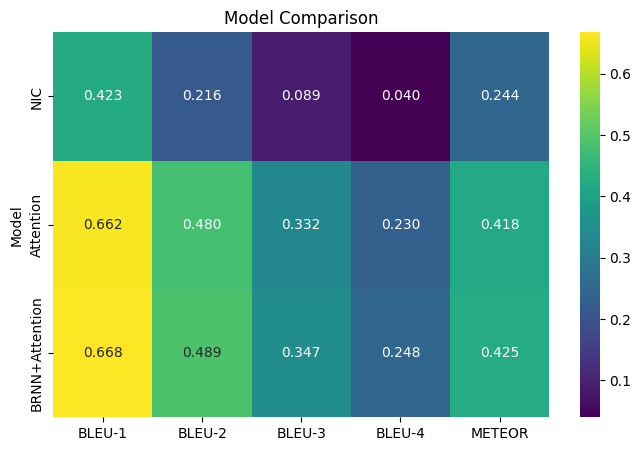

In [37]:
# =========================================
# 🔥 RESULTS HEATMAP
# =========================================

plt.figure(figsize=(8,5))

sns.heatmap(

    results_df.set_index("Model"),

    annot=True,

    cmap="viridis",

    fmt=".3f"
)

plt.title(

    "Model Comparison"
)

plt.show()

**MULTI-MODULE**


In [38]:
# =========================================
# ⚙️ MULTIMODAL SETUP
# =========================================

import spacy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO

from transformers import (
    GPT2LMHeadModel,
    GPT2TokenizerFast
)

# =========================================
# 🧠 LOAD SPACY
# =========================================

nlp = spacy.load("en_core_web_sm")

# =========================================
# 🖼️ LOAD YOLO
# =========================================

yolo = YOLO("yolov8n.pt")

# =========================================
# 🤖 LOAD GPT2
# =========================================

tokenizer = GPT2TokenizerFast.from_pretrained(
    "gpt2"
)

gpt2 = GPT2LMHeadModel.from_pretrained(
    "gpt2"
).to(DEVICE)

gpt2.eval()

print("✅ Multimodal models loaded")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Multimodal models loaded


In [39]:
# =========================================
# 🧠 EXTRACT Sc (Semantic Concepts)
# =========================================

def extract_sc(caption):

    doc = nlp(caption)

    concepts = []

    for token in doc:

        if token.pos_ in ["NOUN", "VERB"]:

            concepts.append(
                token.lemma_.lower()
            )

    return list(set(concepts))


# =========================================
# 🔍 TEST Sc
# =========================================

caption = "a man riding a bike"

sc = extract_sc(caption)

print("Caption:", caption)

print("Sc:", sc)

Caption: a man riding a bike
Sc: ['bike', 'rid', 'man']


In [40]:
# =========================================
# 🖼️ EXTRACT Si (YOLO OBJECTS)
# =========================================

def extract_si(
    image_tensor,
    conf_th=0.3
):

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3,1,1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3,1,1)

    # =====================================
    # 🔄 DENORMALIZE
    # =====================================

    image = image_tensor.cpu()

    image = image * std + mean

    image = image.permute(
        1,2,0
    ).numpy()

    image = image * 255

    image = np.clip(
        image,
        0,
        255
    ).astype(np.uint8)

    # =====================================
    # 🔥 YOLO INFERENCE
    # =====================================

    results = yolo(
        image,
        verbose=False
    )[0]

    if len(results.boxes) == 0:

        return []

    names = results.names

    detected = []

    for cls, conf in zip(
        results.boxes.cls,
        results.boxes.conf
    ):

        if float(conf) >= conf_th:

            detected.append(
                names[int(cls)]
            )

    return list(set(detected))


# =========================================
# 🔍 TEST Si
# =========================================

img, _, _ = next(iter(val_loader))

objects = extract_si(img[0])

print("Detected objects:", objects)

Detected objects: ['person', 'bottle', 'cup', 'dining table', 'tv', 'chair']


In [41]:
# =========================================
# 🔗 FUSION Sc ∪ Si
# =========================================

STOPWORDS = {

    "a",
    "an",
    "the",
    "in",
    "on",
    "at",
    "with",
    "and",
    "of"
}

def clean_tokens(tokens):

    return [

        t.lower()

        for t in tokens

        if t.lower() not in STOPWORDS
    ]


def fuse_sc_si(sc, si):

    sc_clean = clean_tokens(sc)

    si_clean = clean_tokens(si)

    concepts = list(
        set(sc_clean + si_clean)
    )

    return concepts


# =========================================
# 🔍 TEST FUSION
# =========================================

sc = ["man", "riding", "bike"]

si = ["person", "bicycle"]

concepts = fuse_sc_si(sc, si)

print("Concepts:", concepts)

Concepts: ['person', 'riding', 'bike', 'man', 'bicycle']


In [42]:
# =========================================
# 🧠 EXTRACT SVO
# =========================================

def extract_svo(caption):

    doc = nlp(caption)

    subject = None

    verb = None

    obj = None

    for token in doc:

        if token.dep_ in [
            "nsubj",
            "nsubjpass"
        ]:

            subject = token.text

        elif token.dep_ == "ROOT":

            verb = token.lemma_

        elif token.dep_ in [
            "dobj",
            "pobj",
            "attr"
        ]:

            obj = token.text

    return subject, verb, obj


# =========================================
# 🔍 TEST SVO
# =========================================

caption = "a man is riding a bike"

subj, verb, obj = extract_svo(
    caption
)

print("Subject:", subj)

print("Verb:", verb)

print("Object:", obj)

Subject: man
Verb: rid
Object: bike


In [43]:
# =========================================
# 🧩 GENERATE CANDIDATES
# =========================================

def generate_candidates_advanced(

    base_caption,

    subj,

    verb,

    obj,

    concepts
):

    candidates = [base_caption]

    concepts = concepts[:5]

    # =====================================
    # 🔹 SVO SENTENCES
    # =====================================

    if subj and verb:

        for c in concepts:

            candidates.append(

                f"{subj} {verb} a {c}"
            )

    # =====================================
    # 🔹 SIMPLE SENTENCES
    # =====================================

    for c in concepts:

        candidates.append(

            f"a {c} in the image"
        )

    return list(set(candidates))


# =========================================
# 🔍 TEST CANDIDATES
# =========================================

base = "a man riding a bike"

sc = extract_sc(base)

si = ["person", "bicycle"]

concepts = fuse_sc_si(sc, si)

subj, verb, obj = extract_svo(base)

candidates = generate_candidates_advanced(

    base,

    subj,

    verb,

    obj,

    concepts
)

print("Candidates:")

for c in candidates:

    print("-", c)

Candidates:
- a bike in the image
- a man in the image
- a man riding a bike
- a bicycle in the image
- a rid in the image
- a person in the image


In [44]:
# =========================================
# 🤖 GPT2 SCORING
# =========================================

def score_sentence(sentence):

    if len(sentence.strip()) == 0:

        return -1e9

    inputs = tokenizer(

        sentence,

        return_tensors="pt"
    ).to(DEVICE)

    with torch.no_grad():

        outputs = gpt2(

            **inputs,

            labels=inputs["input_ids"]
        )

    loss = outputs.loss.item()

    length = len(sentence.split())

    score = -loss / max(length, 1)

    return score


# =========================================
# 🔍 TEST GPT2
# =========================================

candidates = [

    "a man riding a bike",

    "a bike in the image",

    "man bike"
]

for c in candidates:

    print(

        c,

        "→",

        score_sentence(c)
    )

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


a man riding a bike → -0.8646029472351074
a bike in the image → -1.23528995513916
man bike → -5.614044666290283


In [45]:
# =========================================
# 🏆 SELECT BEST CAPTION
# =========================================

def select_best_caption(candidates):

    best_caption = None

    best_score = -1e9

    for c in candidates:

        s = score_sentence(c)

        if s > best_score:

            best_score = s

            best_caption = c

    return best_caption


# =========================================
# 🔍 TEST BEST CAPTION
# =========================================

best = select_best_caption(
    candidates
)

print("Best:", best)

Best: a man riding a bike


In [46]:
# =========================================
# 🚀 SMART CAPTION
# =========================================

def smart_caption(
    model,
    image
):

    # =====================================
    # 🔹 BASE CAPTION
    # =====================================

    base_caption = generate_caption(
        model,
        image
    )

    # =====================================
    # 🔹 Sc EXTRACTION
    # =====================================

    sc = extract_sc(base_caption)

    # =====================================
    # 🔹 Si EXTRACTION
    # =====================================

    si = extract_si(image)

    # =====================================
    # 🔹 FUSION
    # =====================================

    concepts = fuse_sc_si(sc, si)

    if len(concepts) == 0:

        return base_caption, base_caption

    # =====================================
    # 🔹 SVO
    # =====================================

    subj, verb, obj = extract_svo(
        base_caption
    )

    # =====================================
    # 🔹 GENERATE CANDIDATES
    # =====================================

    candidates = generate_candidates_advanced(

        base_caption,

        subj,

        verb,

        obj,

        concepts
    )

    # =====================================
    # 🔹 GPT2 RERANKING
    # =====================================

    final_caption = select_best_caption(
        candidates
    )

    return base_caption, final_caption


# =========================================
# 🔍 TEST SMART CAPTION
# =========================================

img, _, _ = next(iter(val_loader))

base, improved = smart_caption(

    model_attn,

    img[0]
)

print("Base:", base)

print("Improved:", improved)

Base: a man in a kitchen preparing food in a kitchen
Improved: a man in a kitchen preparing food in a kitchen


In [47]:
# =========================================
# 📊 EVALUATE BEFORE / AFTER
# =========================================

def evaluate_before_after(

    model,

    dataset,

    max_samples=100
):

    refs = []

    hyps_base = []

    hyps_improved = []

    # =====================================
    # 🔥 HANDLE SUBSET
    # =====================================

    if hasattr(dataset, "dataset"):

        real_dataset = dataset.dataset

        indices = dataset.indices

    else:

        real_dataset = dataset

        indices = range(len(dataset))

    total = min(

        len(indices),

        max_samples
    )

    # =====================================
    # 🔁 LOOP
    # =====================================

    for idx in tqdm(indices[:total]):

        img_id = real_dataset.ids[idx]

        img, _, _ = real_dataset[idx]

        references = real_dataset.data[
            img_id
        ]

        references = [

            r.split()

            for r in references
        ]

        # =================================
        # 🔹 BEFORE
        # =================================

        base_caption = generate_caption(

            model,

            img
        )

        base_tokens = base_caption.split()

        # =================================
        # 🔹 AFTER
        # =================================

        _, improved_caption = smart_caption(

            model,

            img
        )

        improved_tokens = improved_caption.split()

        # =================================
        # 🔥 SKIP EMPTY
        # =================================

        if (

            len(base_tokens) == 0

            or

            len(improved_tokens) == 0
        ):

            continue

        refs.append(references)

        hyps_base.append(base_tokens)

        hyps_improved.append(improved_tokens)

    return refs, hyps_base, hyps_improved

In [48]:
# =========================================
# 📊 EVALUATE BEFORE / AFTER
# =========================================

def evaluate_before_after(

    model,

    dataset,

    max_samples=100
):

    refs = []

    hyps_base = []

    hyps_improved = []

    # =====================================
    # 🔥 HANDLE SUBSET
    # =====================================

    if hasattr(dataset, "dataset"):

        real_dataset = dataset.dataset

        indices = dataset.indices

    else:

        real_dataset = dataset

        indices = range(len(dataset))

    total = min(

        len(indices),

        max_samples
    )

    # =====================================
    # 🔁 LOOP
    # =====================================

    for idx in tqdm(indices[:total]):

        img_id = real_dataset.ids[idx]

        img, _, _ = real_dataset[idx]

        references = real_dataset.data[
            img_id
        ]

        references = [

            r.split()

            for r in references
        ]

        # =================================
        # 🔹 BEFORE
        # =================================

        base_caption = generate_caption(

            model,

            img
        )

        base_tokens = base_caption.split()

        # =================================
        # 🔹 AFTER
        # =================================

        _, improved_caption = smart_caption(

            model,

            img
        )

        improved_tokens = improved_caption.split()

        # =================================
        # 🔥 SKIP EMPTY
        # =================================

        if (

            len(base_tokens) == 0

            or

            len(improved_tokens) == 0
        ):

            continue

        refs.append(references)

        hyps_base.append(base_tokens)

        hyps_improved.append(improved_tokens)

    return refs, hyps_base, hyps_improved

In [49]:
# =========================================
# 📊 COMPUTE ALL METRICS
# =========================================

def compute_all_metrics(

    refs,

    hyps
):

    bleu1, bleu2, bleu3, bleu4 = (

        compute_bleu(
            refs,
            hyps
        )
    )

    meteor = compute_meteor(

        refs,

        hyps
    )

    return bleu1, bleu4, meteor

In [50]:
# =========================================
# 🚀 BEFORE VS AFTER EVALUATION
# =========================================

refs, base_caps, improved_caps = (

    evaluate_before_after(

        model_attn,

        val_data,

        max_samples=100
    )
)

# =====================================
# 📊 BEFORE
# =====================================

b1_base, b4_base, m_base = (

    compute_all_metrics(

        refs,

        base_caps
    )
)

# =====================================
# 📊 AFTER
# =====================================

b1_imp, b4_imp, m_imp = (

    compute_all_metrics(

        refs,

        improved_caps
    )
)

# =====================================
# 🖨️ RESULTS
# =====================================

print("\n===== BEFORE =====")

print("BLEU-1:", b1_base)

print("BLEU-4:", b4_base)

print("METEOR:", m_base)

print("\n===== AFTER =====")

print("BLEU-1:", b1_imp)

print("BLEU-4:", b4_imp)

print("METEOR:", m_imp)

100%|██████████| 100/100 [00:17<00:00,  5.68it/s]



===== BEFORE =====
BLEU-1: 0.6574642126789366
BLEU-4: 0.2349939668503624
METEOR: 0.42010304049105607

===== AFTER =====
BLEU-1: 0.6574642126789366
BLEU-4: 0.2349939668503624
METEOR: 0.42010304049105607


In [51]:
# =========================================
# 📋 COMPARISON TABLE
# =========================================

comparison_df = pd.DataFrame({

    "Metric": [

        "BLEU-1",

        "BLEU-4",

        "METEOR"
    ],

    "Before": [

        b1_base,

        b4_base,

        m_base
    ],

    "After": [

        b1_imp,

        b4_imp,

        m_imp
    ]
})

print(comparison_df)

   Metric    Before     After
0  BLEU-1  0.657464  0.657464
1  BLEU-4  0.234994  0.234994
2  METEOR  0.420103  0.420103


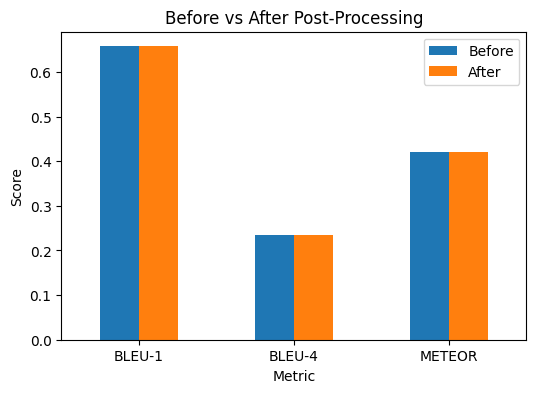

In [52]:
# =========================================
# 📊 VISUALIZATION
# =========================================

comparison_df.set_index("Metric").plot(

    kind="bar",

    figsize=(6,4)
)

plt.title(

    "Before vs After Post-Processing"
)

plt.ylabel("Score")

plt.xticks(rotation=0)

plt.show()

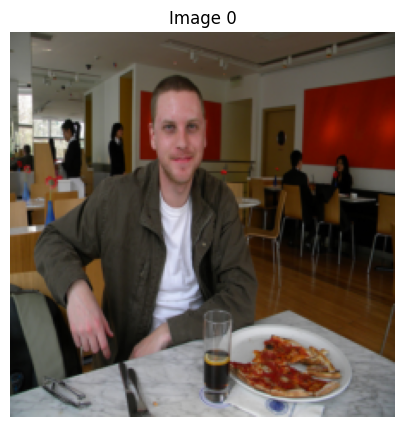


IMAGE: 0

BASE CAPTION:
a man in a kitchen preparing food in a kitchen

IMPROVED CAPTION:
a man in a kitchen preparing food in a kitchen

YOLO OBJECTS:
['person', 'bottle', 'cup', 'dining table', 'tv', 'chair']

Sc Concepts:
['kitchen', 'prepare', 'food', 'man']

FUSED Concepts:
['person', 'bottle', 'cup', 'dining table', 'prepare', 'kitchen', 'tv', 'man', 'chair', 'food']


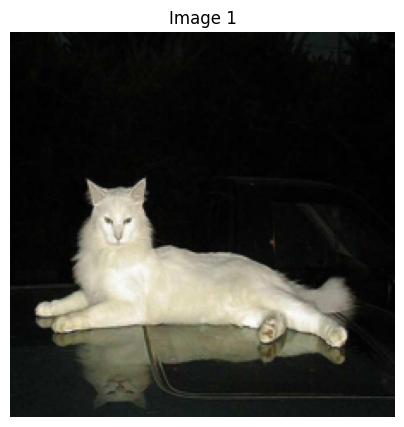


IMAGE: 1

BASE CAPTION:
a cat sitting on a couch with a cat

IMPROVED CAPTION:
a cat sitting on a couch with a cat

YOLO OBJECTS:
['cat']

Sc Concepts:
['cat', 'sit', 'couch']

FUSED Concepts:
['cat', 'sit', 'couch']


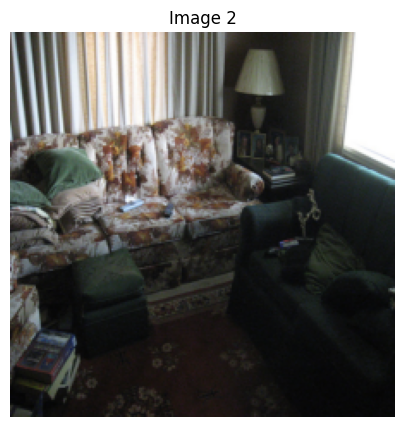


IMAGE: 2

BASE CAPTION:
a cat laying on a couch next to a window

IMPROVED CAPTION:
a cat laying on a couch next to a window

YOLO OBJECTS:
['book']

Sc Concepts:
['cat', 'couch', 'window', 'lay']

FUSED Concepts:
['cat', 'couch', 'window', 'book', 'lay']


In [53]:
# =========================================
# 🔍 QUALITATIVE MULTIMODAL ANALYSIS
# =========================================

model_attn.eval()

for i in range(3):

    # =====================================
    # 🖼️ LOAD IMAGE
    # =====================================

    img, _, _ = val_data[i]

    # =====================================
    # 🔥 GENERATE CAPTIONS
    # =====================================

    with torch.no_grad():

        base, improved = smart_caption(

            model_attn,

            img
        )

    # =====================================
    # 🔥 YOLO OBJECTS
    # =====================================

    objects = extract_si(img)

    # =====================================
    # 🔄 DENORMALIZE IMAGE
    # =====================================

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3,1,1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3,1,1)

    image = img.cpu()

    image = image * std + mean

    image = image.permute(
        1,2,0
    ).numpy()

    image = np.clip(
        image,
        0,
        1
    )

    # =====================================
    # 🖼️ SHOW IMAGE
    # =====================================

    plt.figure(figsize=(5,5))

    plt.imshow(image)

    plt.title(f"Image {i}")

    plt.axis("off")

    plt.show()

    # =====================================
    # 📝 RESULTS
    # =====================================

    print("\n====================")

    print("IMAGE:", i)

    print("\nBASE CAPTION:")

    print(base)

    print("\nIMPROVED CAPTION:")

    print(improved)

    print("\nYOLO OBJECTS:")

    print(objects)

    print("\nSc Concepts:")

    print(extract_sc(base))

    print("\nFUSED Concepts:")

    print(
        fuse_sc_si(
            extract_sc(base),
            objects
        )
    )